# Notebook 11 — Local ViT-B/16 preprocessing

Chuyển chính xác phần DICOM preprocessing của nhánh ViT từ notebook Kaggle ensemble cuối sang local.

**Nguồn chuẩn:** `08_model_ensemble_kaggle_dataset_ready.ipynb`, Cell 7 và Cell 9.

Notebook dùng series mapping đã export trong `demo_sample/series_selection.csv`; không tự chọn lại series. Output là cache uint8 36-slice, chưa phải prediction.

In [1]:
from pathlib import Path
import sys, json, time
import numpy as np
import pandas as pd
from IPython.display import display, Image

def find_project_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    for candidate in [start, *start.parents]:
        if (candidate / "src" / "rsna_knee").is_dir():
            return candidate
    raise FileNotFoundError("Could not find project root containing src/rsna_knee")

PROJECT_ROOT = find_project_root()
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))

print("Project root:", PROJECT_ROOT)
print("Python:", sys.version.split()[0])

Project root: C:\Users\THINH DINH\Desktop\space\rsna-knee-abnormality-detection
Python: 3.13.9


In [2]:
from rsna_knee.dicom.sample import load_demo_sample
from rsna_knee.preprocessing.vit import (
    IMAGE_SIZE, MAX_TOTAL_SLICES, SLICES_PER_SERIES, PLANE_ORDER,
    preprocess_vit_study,
)

sample_candidates = [
    Path(r"C:\rsna_demo\demo_sample"),
    PROJECT_ROOT / "demo" / "input" / "demo_sample",
]
SAMPLE_SOURCE = next((p for p in sample_candidates if p.exists()), sample_candidates[0])
if not SAMPLE_SOURCE.exists():
    raise FileNotFoundError(
        f"Local demo sample not found: {SAMPLE_SOURCE}. "
        "Check Phase 1 extraction and update SAMPLE_SOURCE."
    )

study = load_demo_sample(SAMPLE_SOURCE)
print("Study UID:", study.study_uid)
print("Sample root:", study.root)
print("Available series:", len(study.series))
print("Source selection:")
display(study.selection)

Study UID: 1.2.826.0.1.3680043.8.498.10095687747295410396510538520594649149
Sample root: C:\rsna_demo\demo_sample
Available series: 5
Source selection:


,model,role_or_plane,SeriesInstanceUID,selection_source
0,DINOv2,SAG_FLUID,1.2.826.0.1.3680043.8.498.37372672584387115708...,primary_cache_equivalent
1,DINOv2,COR_FLUID,1.2.826.0.1.3680043.8.498.21497837050858589852...,primary_cache_equivalent
2,DINOv2,AX_FLUID,1.2.826.0.1.3680043.8.498.67495435033389756963...,primary_cache_equivalent
3,DINOv2,SAG_NONFLUID,1.2.826.0.1.3680043.8.498.10791858932231443712...,supplementary_fallback
4,DINOv2,COR_NONFLUID,1.2.826.0.1.3680043.8.498.12451507871565834868...,supplementary_fallback
5,ViT-B/16,Sagittal,1.2.826.0.1.3680043.8.498.37372672584387115708...,highest_fluid_fat_priority_per_plane
6,ViT-B/16,Coronal,1.2.826.0.1.3680043.8.498.21497837050858589852...,highest_fluid_fat_priority_per_plane
7,ViT-B/16,Axial,1.2.826.0.1.3680043.8.498.67495435033389756963...,highest_fluid_fat_priority_per_plane


In [3]:
started = time.time()
result = preprocess_vit_study(study)
elapsed = time.time() - started

print("========== VIT PREPROCESSING ==========")
print("Study UID:", result.study_uid)
print("Valid slices:", result.n_valid_slices, "/", MAX_TOTAL_SLICES)
print("Series used:", result.n_series_used, "/", len(PLANE_ORDER))
print("Elapsed seconds:", round(elapsed, 2))
display(pd.DataFrame(result.diagnostics))

========== VIT PREPROCESSING ==========
Study UID: 1.2.826.0.1.3680043.8.498.10095687747295410396510538520594649149
Valid slices: 36 / 36
Series used: 3 / 3
Elapsed seconds: 0.24


,StudyInstanceUID,plane,series_uid,status,n_files,n_decoded,error,sort_mode
0,1.2.826.0.1.3680043.8.498.10095687747295410396...,Sagittal,1.2.826.0.1.3680043.8.498.37372672584387115708...,ok,36,12,,ImagePositionPatient
1,1.2.826.0.1.3680043.8.498.10095687747295410396...,Coronal,1.2.826.0.1.3680043.8.498.21497837050858589852...,ok,30,12,,ImagePositionPatient
2,1.2.826.0.1.3680043.8.498.10095687747295410396...,Axial,1.2.826.0.1.3680043.8.498.67495435033389756963...,ok,32,12,,ImagePositionPatient


In [4]:
print("========== TENSOR CONTRACT ==========")
arrays = {
    "images": result.images,
    "valid": result.valid,
    "plane_ids": result.plane_ids,
    "fluid": result.fluid,
    "fat": result.fat,
    "positions": result.positions,
}
for name, arr in arrays.items():
    print(f"{name:12s} shape={arr.shape!s:22s} dtype={arr.dtype} finite={np.isfinite(arr).all()}")

assert result.images.shape == (36, 224, 224)
assert result.images.dtype == np.uint8
assert result.valid.shape == (36,)
assert result.plane_ids.shape == (36,)
assert result.fluid.shape == (36,)
assert result.fat.shape == (36,)
assert result.positions.shape == (36,)
assert result.n_valid_slices > 0
assert set(np.unique(result.plane_ids[result.valid.astype(bool)])).issubset({0, 1, 2})
assert np.isfinite(result.positions).all()
print("[PASS] fixed tensor shapes, dtypes, valid plane IDs and finite positions")

========== TENSOR CONTRACT ==========
images       shape=(36, 224, 224)         dtype=uint8 finite=True
valid        shape=(36,)                  dtype=uint8 finite=True
plane_ids    shape=(36,)                  dtype=int8 finite=True
fluid        shape=(36,)                  dtype=int8 finite=True
fat          shape=(36,)                  dtype=int8 finite=True
positions    shape=(36,)                  dtype=float32 finite=True
[PASS] fixed tensor shapes, dtypes, valid plane IDs and finite positions


Sagittal: cache index=6, position=0.5429


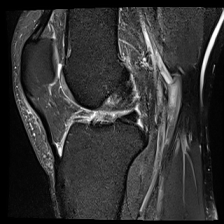

Coronal: cache index=18, position=0.5517


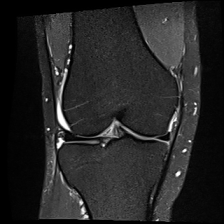

Axial: cache index=30, position=0.5484


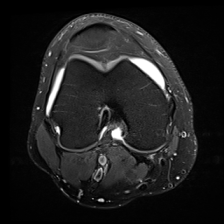

In [5]:
# Preview one valid slice from each available anatomical plane.
from PIL import Image as PILImage

for plane, plane_id in (("Sagittal", 0), ("Coronal", 1), ("Axial", 2)):
    indices = np.flatnonzero((result.valid > 0) & (result.plane_ids == plane_id))
    if len(indices) == 0:
        print(f"{plane}: no valid slices")
        continue
    idx = int(indices[len(indices) // 2])
    print(f"{plane}: cache index={idx}, position={result.positions[idx]:.4f}")
    display(PILImage.fromarray(result.images[idx], mode="L"))

In [6]:
OUTPUT_DIR = PROJECT_ROOT / "demo" / "output" / "vit_preprocessing"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

npz_path = OUTPUT_DIR / "vit_preprocessed_sample.npz"
diagnostics_path = OUTPUT_DIR / "vit_preprocessing_diagnostics.csv"
summary_path = OUTPUT_DIR / "vit_preprocessing_summary.json"

np.savez_compressed(
    npz_path,
    images=result.images,
    valid=result.valid,
    plane_ids=result.plane_ids,
    fluid=result.fluid,
    fat=result.fat,
    positions=result.positions,
    plane_order=np.asarray(PLANE_ORDER),
    series_uids=np.asarray([result.series_uids[p] for p in PLANE_ORDER]),
    study_uid=np.asarray(result.study_uid),
)
pd.DataFrame(result.diagnostics).to_csv(diagnostics_path, index=False)

summary = {
    "study_instance_uid": result.study_uid,
    "source_notebook": "08_model_ensemble_kaggle_dataset_ready.ipynb",
    "source_cells": [7, 9],
    "preprocessing": {
        "image_size": IMAGE_SIZE,
        "slices_per_series": SLICES_PER_SERIES,
        "max_series_per_study": len(PLANE_ORDER),
        "max_total_slices": MAX_TOTAL_SLICES,
        "percentile_clip": [1.0, 99.5],
        "resize_interpolation": "cv2.INTER_AREA",
        "normalization_applied_here": False,
        "output_dtype": str(result.images.dtype),
    },
    "model_inputs": {
        "images_shape": list(result.images.shape),
        "valid_shape": list(result.valid.shape),
        "plane_ids_shape": list(result.plane_ids.shape),
        "n_valid_slices": result.n_valid_slices,
        "n_series_used": result.n_series_used,
    },
    "series_uids": result.series_uids,
    "diagnostics": result.diagnostics,
    "elapsed_seconds": elapsed,
}
summary_path.write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding="utf-8")

print("Saved:", npz_path)
print("Saved:", diagnostics_path)
print("Saved:", summary_path)

Saved: C:\Users\THINH DINH\Desktop\space\rsna-knee-abnormality-detection\demo\output\vit_preprocessing\vit_preprocessed_sample.npz
Saved: C:\Users\THINH DINH\Desktop\space\rsna-knee-abnormality-detection\demo\output\vit_preprocessing\vit_preprocessing_diagnostics.csv
Saved: C:\Users\THINH DINH\Desktop\space\rsna-knee-abnormality-detection\demo\output\vit_preprocessing\vit_preprocessing_summary.json


## 5. CRITERIA — Phase 2D preprocessing

- [ ] Three planes are mapped from the Phase 1 `series_selection.csv` (or partial-series warnings are explained).
- [ ] Per-series sort and decode diagnostics are recorded.
- [ ] Up to 12 slices per selected plane are decoded and normalized.
- [ ] `images` has shape `[36, 224, 224]`, dtype `uint8`.
- [ ] `valid`, `plane_ids`, `fluid`, `fat`, `positions` each have shape `[36]`.
- [ ] Valid slices carry plane IDs 0/1/2; padded slots remain invalid.
- [ ] The saved NPZ, diagnostics CSV and summary JSON exist.

**Important:** images remain grayscale uint8. Do not apply `/255` or ImageNet normalization here; the model forward method performs that normalization internally.